# 🚕 Q-Learning en Taxi-v4 — Trabajo en casa

En este ejercicio aplicará Q-Learning al ambiente **Taxi-v4** de Gymnasium.

La lógica es la misma trabajada en FrozenLake:

$$
(s_t,a_t) \rightarrow (r_{t+1},s_{t+1})
$$

y la actualización:

$$
Q(s_t,a_t)
\leftarrow
Q(s_t,a_t)
+
\alpha
\left[
r_{t+1}
+
\gamma \max_a Q(s_{t+1},a)
-
Q(s_t,a_t)
\right]
$$

## Objetivo

Implementar y analizar un agente Q-Learning capaz de aprender a recoger un pasajero y llevarlo a su destino.


## 1. Preparación

Instale Gymnasium si es necesario:

```bash
pip install gymnasium[toy-text]
```


In [1]:
import gymnasium as gym
import numpy as np
import random
import matplotlib.pyplot as plt

from IPython.display import HTML
from matplotlib import animation


## 2. Crear el ambiente

Taxi tiene un número de estados mucho mayor que FrozenLake.

Cada estado codifica:

- posición del taxi,
- ubicación del pasajero,
- destino del pasajero.

Las acciones posibles son:

| Acción | Significado |
|---|---|
| 0 | South |
| 1 | North |
| 2 | East |
| 3 | West |
| 4 | Pickup |
| 5 | Dropoff |


In [2]:
env = gym.make("Taxi-v4", render_mode="rgb_array")

print("Número de estados:", env.observation_space.n)
print("Número de acciones:", env.action_space.n)


# Semillas para que los resultados sean reproducibles
SEED = 0
random.seed(SEED); np.random.seed(SEED)
env.reset(seed=SEED); env.action_space.seed(SEED)


Número de estados: 500
Número de acciones: 6


0

### Pregunta 1

¿Cuántos estados y cuántas acciones tiene Taxi-v4?

Explique brevemente por qué Taxi tiene muchos más estados que FrozenLake.


**Respuesta:**

Taxi-v4 tiene **500 estados** y **6 acciones** (South, North, East, West, Pickup, Dropoff).

Tiene muchos más estados que FrozenLake 4x4 (16) porque el estado no es solo la posición del taxi: combina **25 posiciones del taxi × 5 ubicaciones del pasajero (4 paradas + dentro del taxi) × 4 destinos = 500**. En FrozenLake el estado es solo la casilla del agente.

## 3. Observar una interacción

Ejecute una acción aleatoria y observe qué devuelve el ambiente.


In [3]:
state, info = env.reset(seed=42)

action = env.action_space.sample()

next_state, reward, terminated, truncated, info = env.step(action)

print("Estado:", state)
print("Acción:", action)
print("Nuevo estado:", next_state)
print("Recompensa:", reward)
print("Terminated:", terminated)


Estado: 386
Acción: 5
Nuevo estado: 386
Recompensa: -10
Terminated: False


### Pregunta 2

En la interacción anterior identifique:

$$
s_t,\quad a_t,\quad r_{t+1},\quad s_{t+1}
$$

¿Qué representa cada elemento?


**Respuesta:**

En la interacción ejecutada (semilla 42, acción aleatoria):

- **s_t = 386**: el estado actual, que codifica posición del taxi, ubicación del pasajero y destino.
- **a_t = 5 (Dropoff)**: la acción elegida al azar por el agente.
- **r_{t+1} = −10**: la recompensa; −10 es la penalización por intentar dejar al pasajero en un lugar donde no corresponde (o sin llevarlo).
- **s_{t+1} = 386**: el siguiente estado; es el mismo porque la acción ilegal no mueve nada.

`terminated = False`: el episodio continúa.

## 4. Inicializar la Q-table

Cada fila corresponde a un estado y cada columna a una acción.

Inicialmente:

$$
Q(s,a)=0
$$


In [4]:
n_states = env.observation_space.n
n_actions = env.action_space.n

Q = np.zeros((n_states, n_actions))

print("Shape de Q:", Q.shape)
Q[:5]


Shape de Q: (500, 6)


array([[0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]])

### Pregunta 3

¿Cuántos valores debe aprender el agente en total?

Calcule:

$$
|\mathcal{S}| \times |\mathcal{A}|
$$


**Respuesta:**

El agente debe aprender **|S| × |A| = 500 × 6 = 3 000 valores** Q(s,a), uno por cada par estado-acción (la forma de la tabla es `(500, 6)`).

## 5. Política $\epsilon$-greedy

Implemente una función que:

- con probabilidad $\epsilon$ seleccione una acción aleatoria;
- en otro caso seleccione:

$$
\arg\max_a Q(s,a)
$$

### Actividad 1
Complete la función.


In [5]:
def choose_action(Q, state, epsilon, env):
    # 1. decidir si explorar o explotar
    if random.random() < epsilon:
        return env.action_space.sample()          # explorar: acción aleatoria
    # 2. explotar: argmax_a Q(s,a) con desempate aleatorio entre acciones iguales
    q_values = Q[state]
    best_actions = np.flatnonzero(q_values == np.max(q_values))
    return int(np.random.choice(best_actions))

## 6. Actualización de Q

La regla de actualización es:

$$
Q(s,a)
\leftarrow
Q(s,a)
+
\alpha
\left[
r+
\gamma\max_{a'}Q(s',a')
-
Q(s,a)
\right]
$$

### Actividad 2
Complete la función.


In [6]:
def update_q(Q, state, action, reward, next_state, alpha, gamma, done=False):
    # Target TD: r + gamma * max_a' Q(s', a')  (si el episodio terminó, no hay futuro)
    best_next = 0.0 if done else np.max(Q[next_state])
    td_target = reward + gamma * best_next
    # Error TD
    td_error = td_target - Q[state, action]
    # Actualización
    Q[state, action] += alpha * td_error
    return td_error

## 7. Entrenamiento

Ahora implemente el ciclo completo de Q-Learning.

En cada episodio:

1. reiniciar el ambiente;
2. escoger una acción;
3. ejecutar `env.step(action)`;
4. actualizar $Q(s,a)$;
5. mover el agente a `next_state`;
6. terminar cuando el episodio finalice.

Use inicialmente:

```python
alpha = 0.1
gamma = 0.95
epsilon = 0.1
episodes = 5000
```

### Actividad 3
Complete la función.


In [7]:
def train_q_learning(
    env,
    Q,
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1,
    max_steps=200
):
    rewards = []

    for episode in range(episodes):
        state, _ = env.reset()
        total_reward = 0

        for _ in range(max_steps):

            # 1: escoger acción (epsilon-greedy)
            action = choose_action(Q, state, epsilon, env)

            # 2: ejecutar acción en el ambiente
            next_state, reward, terminated, truncated, _ = env.step(action)

            # 3: actualizar Q (solo "terminated" corta el bootstrap; "truncated" es un límite de tiempo)
            update_q(Q, state, action, reward, next_state, alpha, gamma, done=terminated)

            # 4: actualizar estado y recompensa acumulada
            state = next_state
            total_reward += reward

            # 5: terminar si corresponde
            if terminated or truncated:
                break

        rewards.append(total_reward)

    return Q, rewards

## 8. Entrenar el agente

Ejecute el entrenamiento una vez haya completado las funciones anteriores.


In [8]:
random.seed(SEED); np.random.seed(SEED); env.action_space.seed(SEED)
Q_initial = np.zeros((n_states, n_actions))

Q_trained, rewards = train_q_learning(
    env,
    Q_initial.copy(),
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1
)


## 9. Curva de aprendizaje

Observe cómo cambia la recompensa durante el entrenamiento.


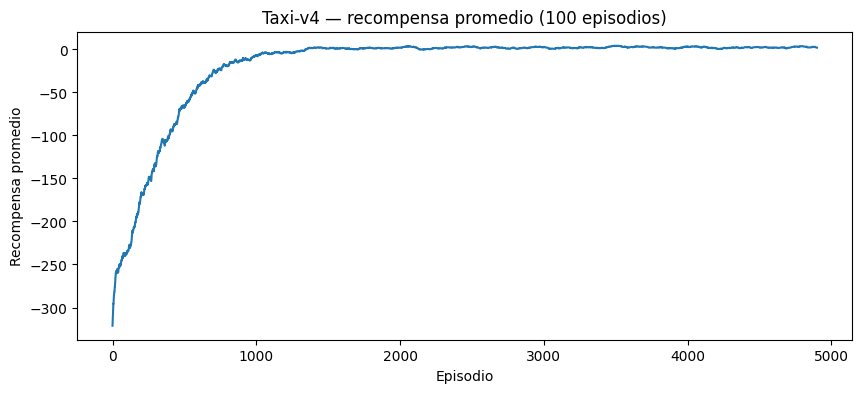

Media móvil en el episodio 100 : -321.2
Media móvil en el episodio 500 : -96.3
Media móvil en el episodio 1000: -13.2
Media móvil en el episodio 2000: 1.5
Media móvil final (ep. 5000)   : 2.1
Primer episodio con media móvil > 0: 1445
Recompensa promedio últimos 500 episodios: 2.38 ± std 8.1


In [9]:
window = 100

moving_average = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 4))
plt.plot(moving_average)
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio")
plt.title(f"Taxi-v4 — recompensa promedio ({window} episodios)")
plt.show()


# Métricas para describir la curva
primer_pos = int(np.argmax(moving_average > 0)) + window
print("Media móvil en el episodio 100 :", round(moving_average[0], 1))
print("Media móvil en el episodio 500 :", round(moving_average[400], 1))
print("Media móvil en el episodio 1000:", round(moving_average[900], 1))
print("Media móvil en el episodio 2000:", round(moving_average[1900], 1))
print("Media móvil final (ep. 5000)   :", round(moving_average[-1], 1))
print("Primer episodio con media móvil > 0:", primer_pos)
print("Recompensa promedio últimos 500 episodios:", round(np.mean(rewards[-500:]), 2), "± std", round(np.std(rewards[-500:]), 1))


### Pregunta 4

Describa la curva de aprendizaje.

- ¿La recompensa promedio mejora?
- ¿Después de aproximadamente cuántos episodios comienza a estabilizarse?
- ¿El comportamiento observado indica convergencia perfecta o solamente una política razonablemente buena?


**Respuesta:**

- **¿Mejora la recompensa?** Sí, mucho. La media móvil (ventana de 100) empieza en ≈ −321 (el taxi casi siempre agota los 200 pasos y acumula penalizaciones), sube a ≈ −96 en el episodio 500, ≈ −13 en el 1000 y ≈ +1.5 en el 2000.
- **¿Cuándo se estabiliza?** Cruza a valores positivos hacia el episodio **≈ 1 450** y a partir de ≈ 2 000 queda oscilando alrededor de +2 (final: +2.1; últimos 500 episodios: 2.38 ± 8.1).
- **¿Convergencia perfecta?** No es una curva perfecta ni sin ruido: durante el entrenamiento se sigue usando ε = 0.1, o sea, 10 % de acciones aleatorias que a veces causan penalizaciones, así que la recompensa de entrenamiento (≈ +2) queda por debajo de la de la política greedy (≈ +8 en la evaluación). Lo que se observa es una **política muy buena (100 % de éxito en ≈ 13 pasos)**, no una prueba formal de convergencia exacta de Q.

## 10. Reproducir un episodio

La siguiente función ejecuta una política greedy usando la Q-table aprendida y guarda los frames del episodio.


In [10]:
def play_episode(env, Q, max_steps=200, seed=None):
    state, _ = env.reset(seed=seed)

    frames = [env.render()]
    total_reward = 0

    for _ in range(max_steps):

        q_values = Q[state]
        max_q = np.max(q_values)

        best_actions = np.flatnonzero(q_values == max_q)
        action = int(np.random.choice(best_actions))

        next_state, reward, terminated, truncated, _ = env.step(action)

        frames.append(env.render())

        total_reward += reward
        state = next_state

        if terminated or truncated:
            break

    return frames, total_reward


def frames_to_video(frames, interval=500):
    fig = plt.figure(figsize=(6, 4))
    plt.axis("off")

    image = plt.imshow(frames[0])

    def update(frame):
        image.set_data(frame)
        return [image]

    anim = animation.FuncAnimation(
        fig,
        update,
        frames=frames,
        interval=interval,
        blit=True,
        repeat=True
    )

    plt.close(fig)
    return HTML(anim.to_jshtml())


## 11. Comparar antes y después

Primero observe un Taxi sin entrenamiento usando una Q-table en cero.


In [11]:
frames_initial, reward_initial = play_episode(
    env,
    Q_initial,
    max_steps=50,
    seed=7
)

print("Recompensa total sin entrenamiento:", reward_initial)
frames_to_video(frames_initial, interval=500)


error: XDG_RUNTIME_DIR is invalid or not set in the environment.


Recompensa total sin entrenamiento: -194


Ahora observe el agente entrenado.


In [12]:
frames_trained, reward_trained = play_episode(
    env,
    Q_trained,
    max_steps=200,
    seed=7
)

print("Recompensa total después del entrenamiento:", reward_trained)
frames_to_video(frames_trained, interval=500)


Recompensa total después del entrenamiento: 10


### Pregunta 5

Compare los dos episodios.

- ¿Qué diferencias observa en el comportamiento del taxi?
- ¿El taxi sin entrenamiento logra completar la tarea?
- ¿El agente entrenado evita acciones innecesarias?
- ¿Qué evidencia visual le permite afirmar que el agente aprendió?


In [13]:
def evaluar(env, Q, n_episodes=200, max_steps=200):
    """Política greedy: recompensa media, pasos medios y % de episodios terminados con éxito."""
    R, S, ok = [], [], 0
    for _ in range(n_episodes):
        s, _ = env.reset(); tot = 0; pasos = 0
        for _ in range(max_steps):
            q = Q[s]; a = int(np.random.choice(np.flatnonzero(q == q.max())))
            s, r, te, tr, _ = env.step(a); tot += r; pasos += 1
            if te or tr: break
        R.append(tot); S.append(pasos); ok += int(te)
    return np.mean(R), np.mean(S), ok / n_episodes

for nombre, Qx in [("Sin entrenar (Q=0)", Q_initial), ("Entrenado (5000 ep.)", Q_trained)]:
    r, p, e = evaluar(env, Qx)
    print(f"{nombre:22s} recompensa media={r:8.2f} | pasos medios={p:6.1f} | éxito={e:.0%}")

Sin entrenar (Q=0)     recompensa media= -766.76 | pasos medios= 194.1 | éxito=8%
Entrenado (5000 ep.)   recompensa media=    8.00 | pasos medios=  13.0 | éxito=100%


**Respuesta:**

- **Sin entrenar** (Q = 0): al ser todos los valores iguales, el desempate aleatorio hace que el taxi se mueva al azar. En el episodio mostrado (semilla 7, 50 pasos) acumuló **−194**, sin completar la tarea; en 200 episodios de evaluación solo terminó con éxito el **8 %** y tardó ≈ 194 pasos en promedio (recompensa media ≈ −767).
- **Entrenado:** en el episodio mostrado obtuvo **+10** en pocos pasos; en la evaluación completó el **100 %** de los episodios en ≈ **13 pasos**, con recompensa media de ≈ **+8**.
- **¿Evita acciones innecesarias?** Sí: va directo hacia el pasajero, hace *Pickup* en la casilla correcta, va al destino y hace *Dropoff*, sin intentar Pickup/Dropoff ilegales (que cuestan −10).
- **Evidencia visual de que aprendió:** trayectoria directa y con propósito frente al deambular aleatorio, la recompensa pasa de muy negativa a positiva y el número de pasos baja de ≈ 194 a ≈ 13.

## 12. Analizar la política aprendida

Seleccione un estado cualquiera y observe los valores aprendidos para sus seis acciones.


In [14]:
state = 123

print("Estado:", state)
print("Q-values:", Q_trained[state])
print("Mejor acción:", np.argmax(Q_trained[state]))


Estado: 123
Q-values: [-4.29025547 -4.24768764 -3.39028405  3.64270877 -5.64590732 -4.76446748]
Mejor acción: 3


In [15]:
nombres_acciones = ["South", "North", "East", "West", "Pickup", "Dropoff"]
taxi_row, taxi_col, pas_loc, dest = env.unwrapped.decode(state)
print("Estado 123 decodificado -> fila taxi:", taxi_row, "| col taxi:", taxi_col, "| pasajero en:", pas_loc, "| destino:", dest)
for n, q in zip(nombres_acciones, Q_trained[state]):
    print(f"  {n:8s} Q = {q:8.3f}")
print("Mejor acción:", nombres_acciones[int(np.argmax(Q_trained[state]))])

Estado 123 decodificado -> fila taxi: 1 | col taxi: 1 | pasajero en: 0 | destino: 3
  South    Q =   -4.290
  North    Q =   -4.248
  East     Q =   -3.390
  West     Q =    3.643
  Pickup   Q =   -5.646
  Dropoff  Q =   -4.764
Mejor acción: West


### Pregunta 6

Para el estado seleccionado:

1. ¿Cuál es la acción con mayor valor Q?
2. ¿Qué significa que una acción tenga un valor Q mayor que otra?
3. ¿Por qué no podemos interpretar $Q(s,a)$ únicamente como la recompensa inmediata de ejecutar la acción?


**Respuesta:**

Estado 123 (decodificado: taxi en fila 1, col 1; pasajero en la parada 0; destino 3):

| Acción | Q |
|---|---|
| South | −4.29 |
| North | −4.25 |
| East | −3.39 |
| **West** | **+3.64** |
| Pickup | −5.65 |
| Dropoff | −4.76 |

1. **La mayor es West (Q ≈ +3.64)**: acerca al taxi a la esquina donde está el pasajero.
2. Un Q mayor significa que, desde ese estado, esa acción lleva a un **mayor retorno descontado esperado** si después se sigue la mejor política; es decir, es mejor opción que las demás.
3. Porque Q(s,a) no es la recompensa inmediata sino el **retorno acumulado futuro**. Aquí moverse cuesta −1 en *cualquier* dirección, pero West vale +3.64 y East −3.39: la diferencia viene del futuro (acercarse al pasajero, recogerlo y entregarlo, que da +20), no del −1 inmediato.

## 13. Experimentación

Modifique **solo uno** de los siguientes hiperparámetros y vuelva a entrenar:

- $\alpha$
- $\gamma$
- $\epsilon$

### Pregunta 7

Compare el nuevo entrenamiento con el original.

Explique cómo el cambio del hiperparámetro afectó:

- velocidad de aprendizaje,
- estabilidad,
- recompensa final,
- comportamiento observado.


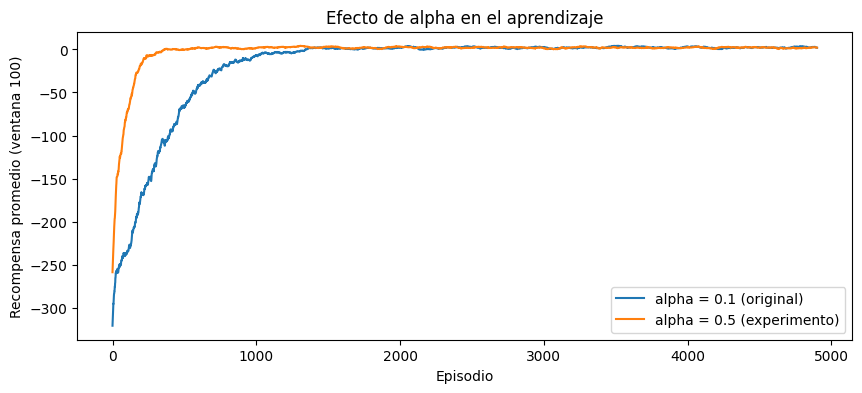

alpha=0.1: 1er episodio con media>0:  1445 | media ep.500:   -96.3 | media últimos 500:  2.38 (std  8.1) | eval greedy: recompensa  7.69, pasos 13.3, éxito 100%
alpha=0.5: 1er episodio con media>0:   462 | media ep.500:     0.2 | media últimos 500:  1.92 (std  7.9) | eval greedy: recompensa  7.92, pasos 13.1, éxito 100%


In [16]:
# Experimento (solo se modifica alpha: 0.1 -> 0.5; gamma y epsilon quedan igual)
random.seed(SEED); np.random.seed(SEED); env.action_space.seed(SEED)
Q_exp, rewards_exp = train_q_learning(env, np.zeros((n_states, n_actions)), episodes=5000, alpha=0.5, gamma=0.95, epsilon=0.1)

ma_orig = np.convolve(rewards,     np.ones(window)/window, mode="valid")
ma_exp  = np.convolve(rewards_exp, np.ones(window)/window, mode="valid")

plt.figure(figsize=(10, 4))
plt.plot(ma_orig, label="alpha = 0.1 (original)")
plt.plot(ma_exp,  label="alpha = 0.5 (experimento)")
plt.xlabel("Episodio"); plt.ylabel("Recompensa promedio (ventana 100)")
plt.title("Efecto de alpha en el aprendizaje"); plt.legend(); plt.show()

for nombre, ma, R, Qx in [("alpha=0.1", ma_orig, rewards, Q_trained), ("alpha=0.5", ma_exp, rewards_exp, Q_exp)]:
    r, p, e = evaluar(env, Qx)
    print(f"{nombre}: 1er episodio con media>0: {int(np.argmax(ma > 0)) + window:5d} | media ep.500: {ma[400]:7.1f} | "
          f"media últimos 500: {np.mean(R[-500:]):5.2f} (std {np.std(R[-500:]):4.1f}) | "
          f"eval greedy: recompensa {r:5.2f}, pasos {p:4.1f}, éxito {e:.0%}")

**Respuesta:**

**Cambio realizado: solo α, de 0.1 a 0.5** (γ = 0.95 y ε = 0.1 sin cambios; misma semilla).

- **Velocidad de aprendizaje:** mucho más rápida. La media móvil pasa a ser positiva en el episodio ≈ **462** (antes ≈ 1 445) y en el episodio 500 ya vale ≈ +0.2 (antes ≈ −96).
- **Estabilidad:** parecida al final: desviación en los últimos 500 episodios de ≈ 7.9 (antes 8.1). Taxi es determinista, así que un α alto no desestabiliza; en un ambiente estocástico un α grande haría que Q oscile más por seguir demasiado el último ruido.
- **Recompensa final:** prácticamente igual (≈ +1.9 vs ≈ +2.4 durante el entrenamiento, y ≈ +7.9 vs ≈ +7.7 en evaluación greedy; la diferencia es ruido de ε = 0.1).
- **Comportamiento:** ambas políticas terminan resolviendo el 100 % de los episodios en ≈ 13 pasos. α solo cambió **qué tan rápido** se llegó a esa política, no la calidad final.

*(Es una sola corrida con una semilla; para afirmarlo con más fuerza habría que repetir con varias semillas.)*

## Entrega

El notebook debe contener:

1. implementación de `choose_action`;
2. implementación de `update_q`;
3. implementación de `train_q_learning`;
4. curva de aprendizaje;
5. visualización del agente antes y después del entrenamiento;
6. respuestas a las siete preguntas.

No es necesario modificar las funciones auxiliares de visualización.
